# ACS visualization examples — all 11 pages

Run using your own Census API key. **No synthetic ACS estimates** will be presented as official results. This notebook uses the included public scripts and saves PNG, SVG, CSV, HTML, and provenance files. Upload the full ZIP first.

In [ ]:
from pathlib import Path
import os, zipfile
from getpass import getpass

# Use an already extracted folder locally, or upload the ZIP in Colab.
project = Path.cwd() / "ACS_Examples_Builder"
if not (project / "build_acs_examples.py").exists():
    try:
        from google.colab import files
        print("Upload ACS_Examples_All_11_Python.zip")
        uploaded = files.upload()
        zip_path = next((Path.cwd()/name for name in uploaded if name.endswith(".zip")), None)
        if zip_path is None:
            raise FileNotFoundError("Please upload the ACS examples ZIP file")
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(Path.cwd())
    except ImportError:
        raise FileNotFoundError("Place or extract ACS_Examples_Builder alongside this notebook")
assert (project / "build_acs_examples.py").exists(), project
print("Project located:", project)

Upload ACS_Examples_All_11_Python.zip


Saving ACS_Examples_All_11_Python_v03.zip to ACS_Examples_All_11_Python_v03.zip
Project located: /content/ACS_Examples_Builder


In [ ]:
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(project/"requirements.txt")])
print("Python dependencies available")

Python dependencies available


In [ ]:
if not os.getenv("CENSUS_API_KEY"):
    os.environ["CENSUS_API_KEY"] = getpass("Enter your own activated Census API key (hidden): ")
if not os.environ["CENSUS_API_KEY"].strip():
    raise ValueError("An activated Census API key is required in API mode")
print("Key configured for this session; it will not be displayed or saved")

Enter your own activated Census API key (hidden): ··········
Key configured for this session; it will not be displayed or saved


In [ ]:
import os
import requests

url = "https://api.census.gov/data/2024/acs/acs1"

params = {
    "get": "NAME,B19013_001E",
    "for": "state:12",
    "key": os.environ["CENSUS_API_KEY"]
}

response = requests.get(
    url,
    params=params,
    timeout=30
)

content_type = response.headers.get("Content-Type", "").lower()

if "json" not in content_type:
    print("API authentication or response validation failed.")
    print("HTTP status:", response.status_code)

    if "Invalid Key" in response.text:
        print("The Census Bureau rejected the API key.")
        print("Verify activation or request a replacement key.")
    else:
        print("The API returned unexpected non-JSON content.")

    raise RuntimeError("Census API preflight check failed.")

response.raise_for_status()
data = response.json()

print("Census API connection successful.")
print("Returned columns:", data[0])
print("State:", data[1][0])
print("Median household income:", data[1][1])

Census API connection successful.
Returned columns: ['NAME', 'B19013_001E', 'state']
State: Florida
Median household income: 77735


In [ ]:
# Run all pages; use ["scatter_plot"] to restrict to a single page.
ONLY_PAGES = None
OUTPUT_ROOT = project / "acs_generated_examples"
cmd = [sys.executable, str(project / "build_acs_examples.py"), "--output-root", str(OUTPUT_ROOT), "--continue-on-error"]
if ONLY_PAGES:
    cmd += ["--only", *ONLY_PAGES]
# Capture and DISPLAY runner messages rather than hiding the errors.
result = subprocess.run(cmd, cwd=project, capture_output=True, text=True)
print("Runner output:\n", result.stdout[-18000:] or "(no output)")
if result.stderr.strip():
    print("Runner diagnostics:\n", result.stderr[-4000:])
print("Process return code:", result.returncode)
if result.returncode != 0:
    print("At least one chart failed. Review the status table and per-chart execution.log files below.")


Runner output:
 
=== Visualizing Uncertainty — 2024 ACS 1-Year; B19013 state estimates and 90% MOEs ===
Generated: uncertainty_acs.png

=== Nested or Non-Mutually Exclusive Categories — 2024 ACS 1-Year; B03002 state categories plus ACS profile DP03 coverage ===
Generated: nested_b03002.png, nested_dp03.png

=== Line Graph — 2021–2024 ACS 1-Year; B19013 state median income, adjusted to 2024 dollars ===
Generated: linegraph_acs_income.png

=== Area Chart — 2021–2024 ACS 1-Year; B17001 state poverty counts ===
Generated: area_chart.png

=== Bubble Chart — 2024 ACS 1-Year; B19013, B17001, B01003 state estimates ===
Generated: bubble_chart.png

=== Scatter Plot — 2024 ACS 1-Year; B19013 and B17001 state estimates ===
Generated: scatter_plot.png

=== Small Multiples — 2021–2024 ACS 1-Year; B17001 state poverty percentages ===
Generated: small_multiples_acs.png

=== Population Pyramid — 2024 ACS 1-Year; B01001 state sex-by-age ===
Generated: population_pyramid_acs.png

=== Boxplot — 2020–2024

,key,status,reason,log_file
0,uncertainty,generated_unreviewed,,outputs/uncertainty/execution.log
1,nested_categories,generated_unreviewed,,outputs/nested_categories/execution.log
2,line_graph,generated_unreviewed,,outputs/line_graph/execution.log
3,area_chart,generated_unreviewed,,outputs/area_chart/execution.log
4,bubble_chart,generated_unreviewed,,outputs/bubble_chart/execution.log
5,scatter_plot,generated_unreviewed,,outputs/scatter_plot/execution.log
6,small_multiples,generated_unreviewed,,outputs/small_multiples/execution.log
7,population_pyramid,generated_unreviewed,,outputs/population_pyramid/execution.log
8,boxplot,generated_unreviewed,,outputs/boxplot/execution.log
9,stacked_area,generated_unreviewed,,outputs/stacked_area/execution.log


Generated: 11 | Failed: 0
PNG files generated: 13


### area_chart: area_chart.png

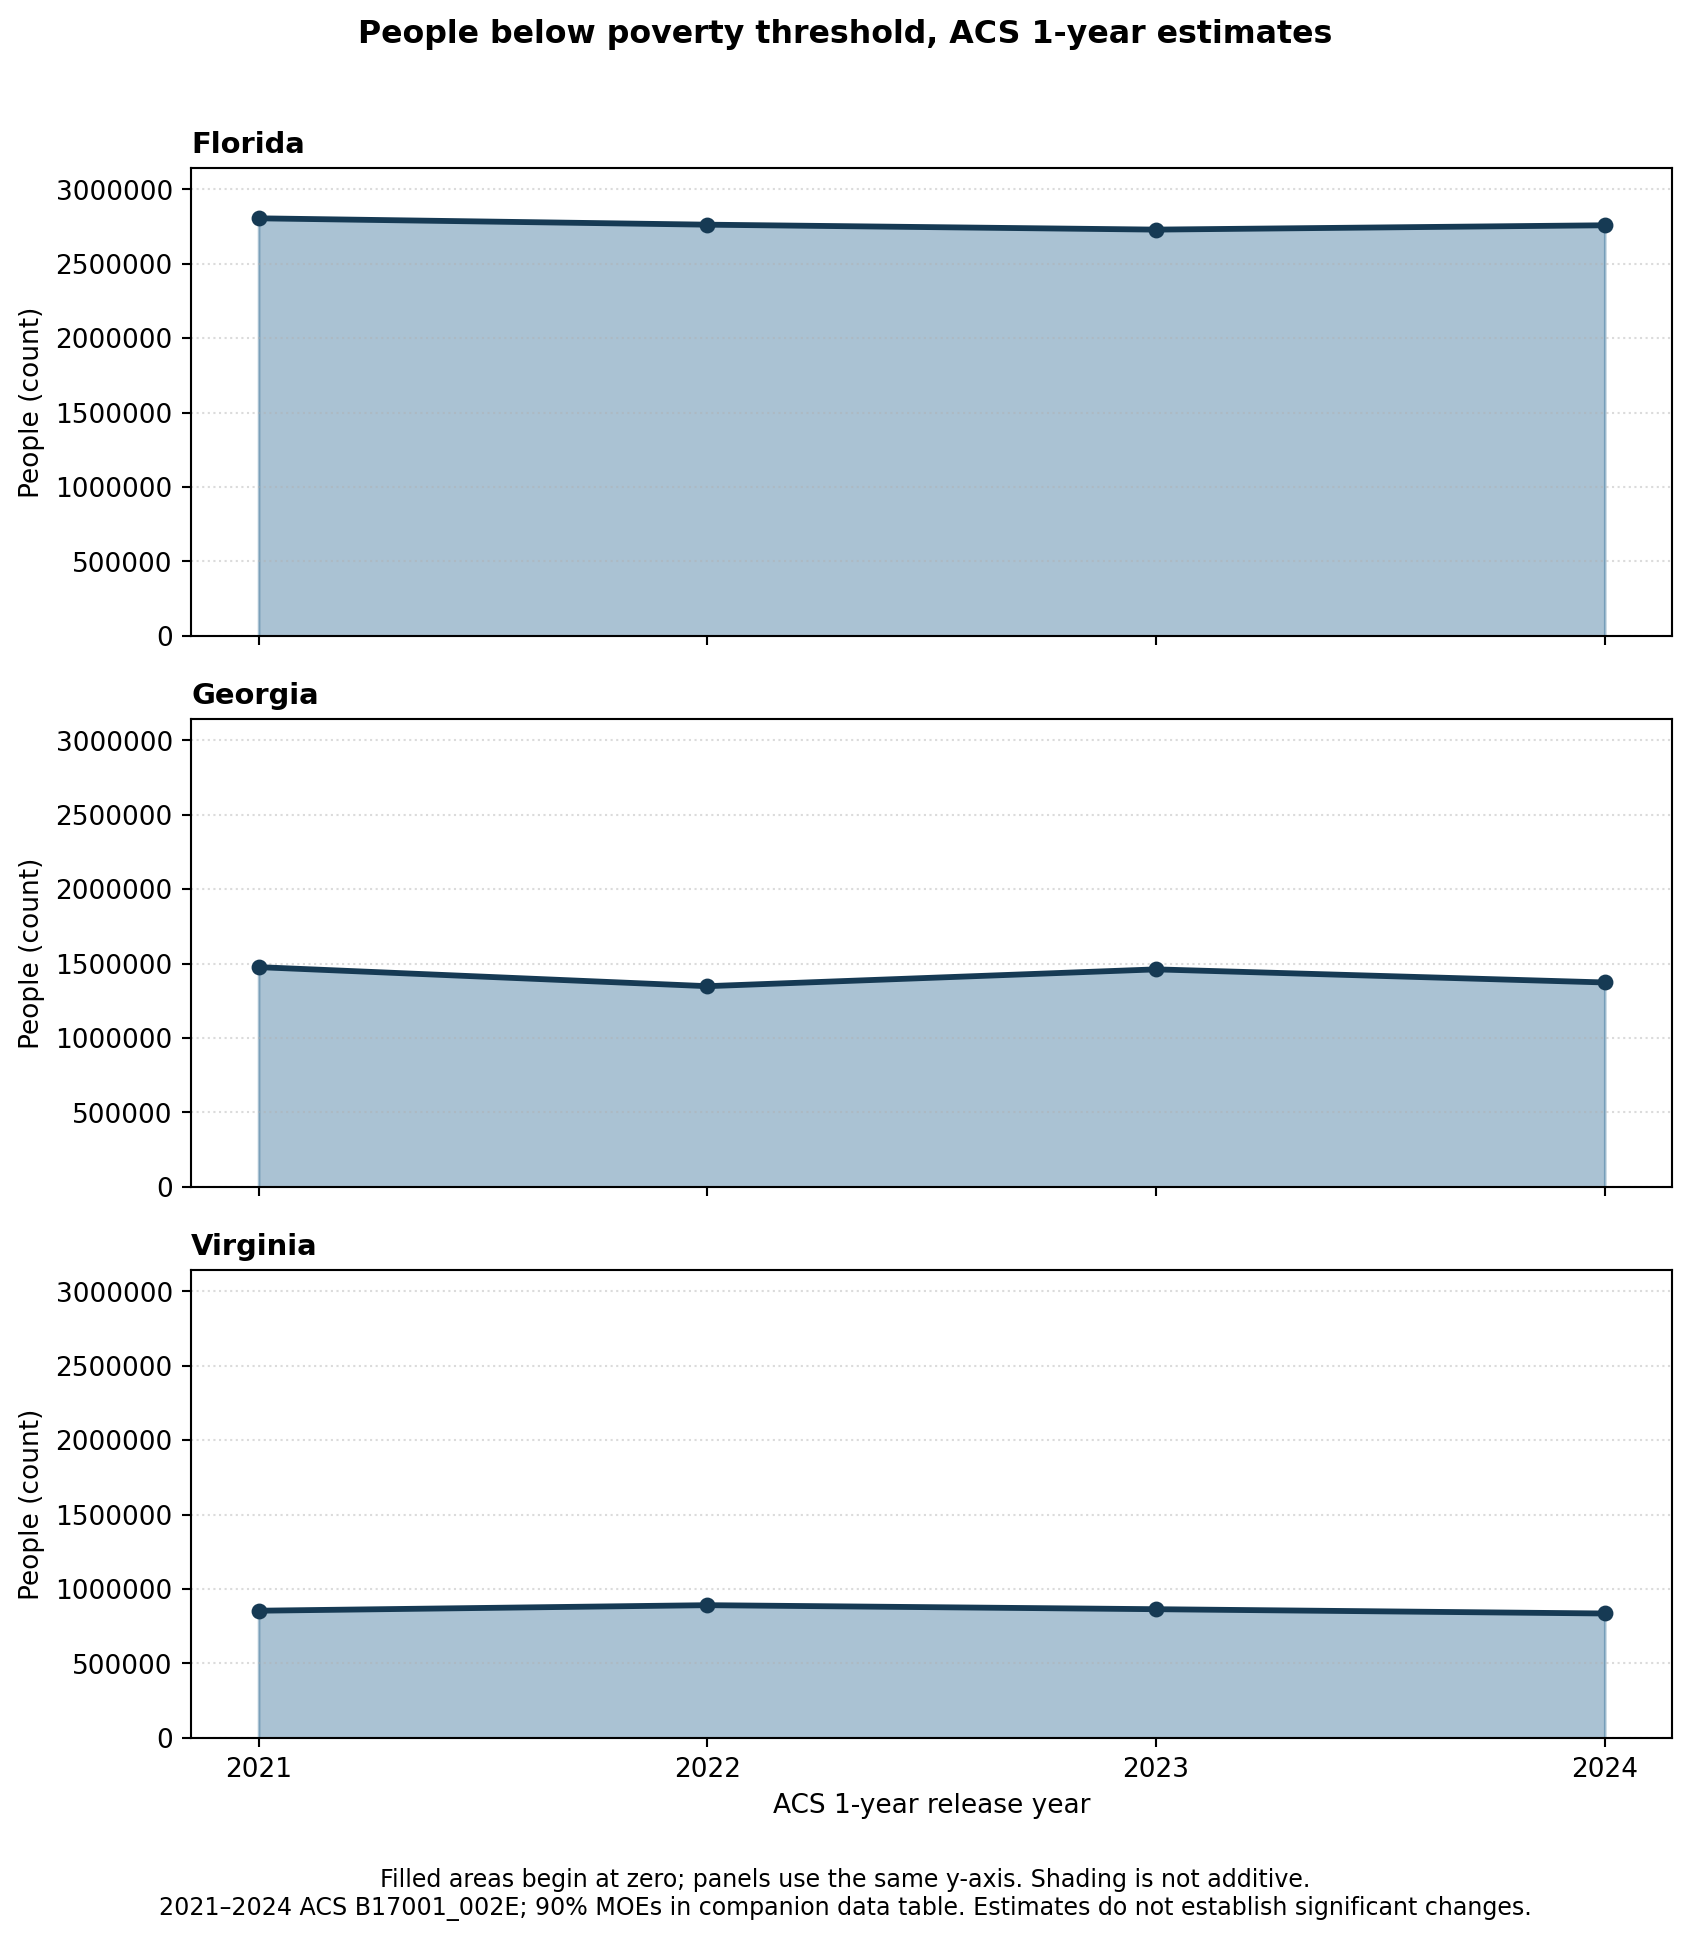

### boxplot: boxplot_acs.png

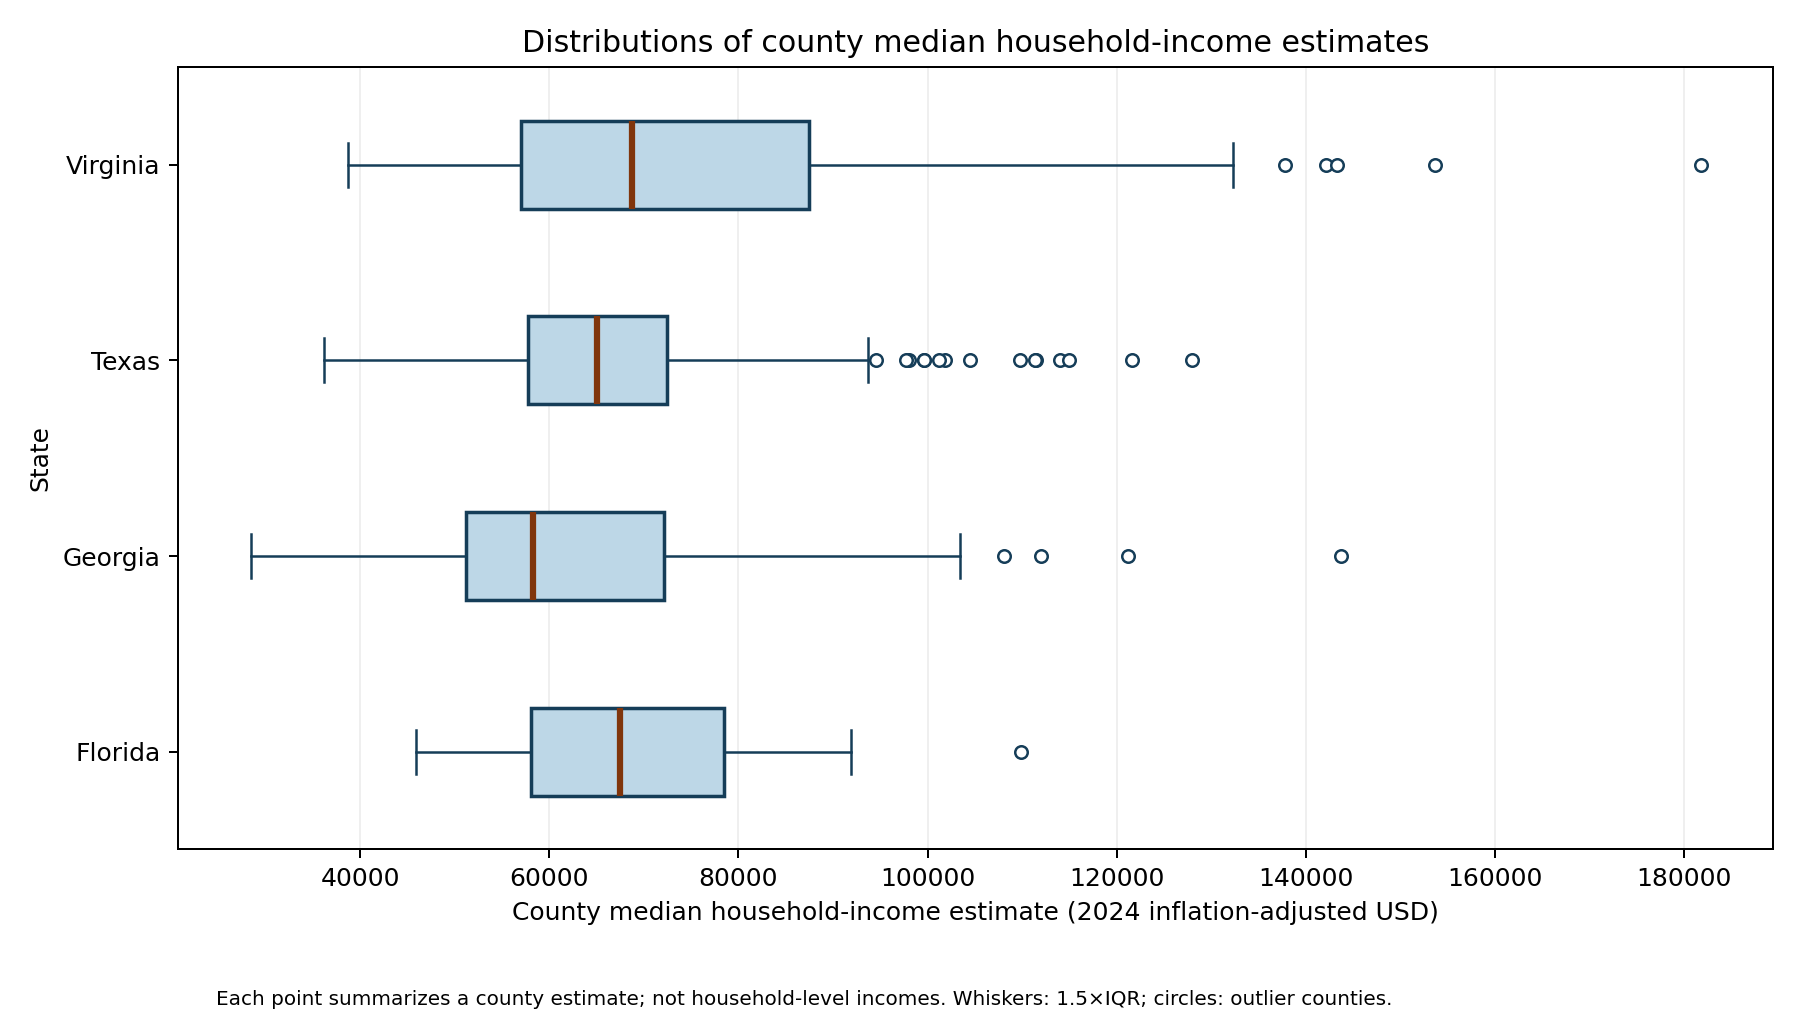

### bubble_chart: bubble_chart.png

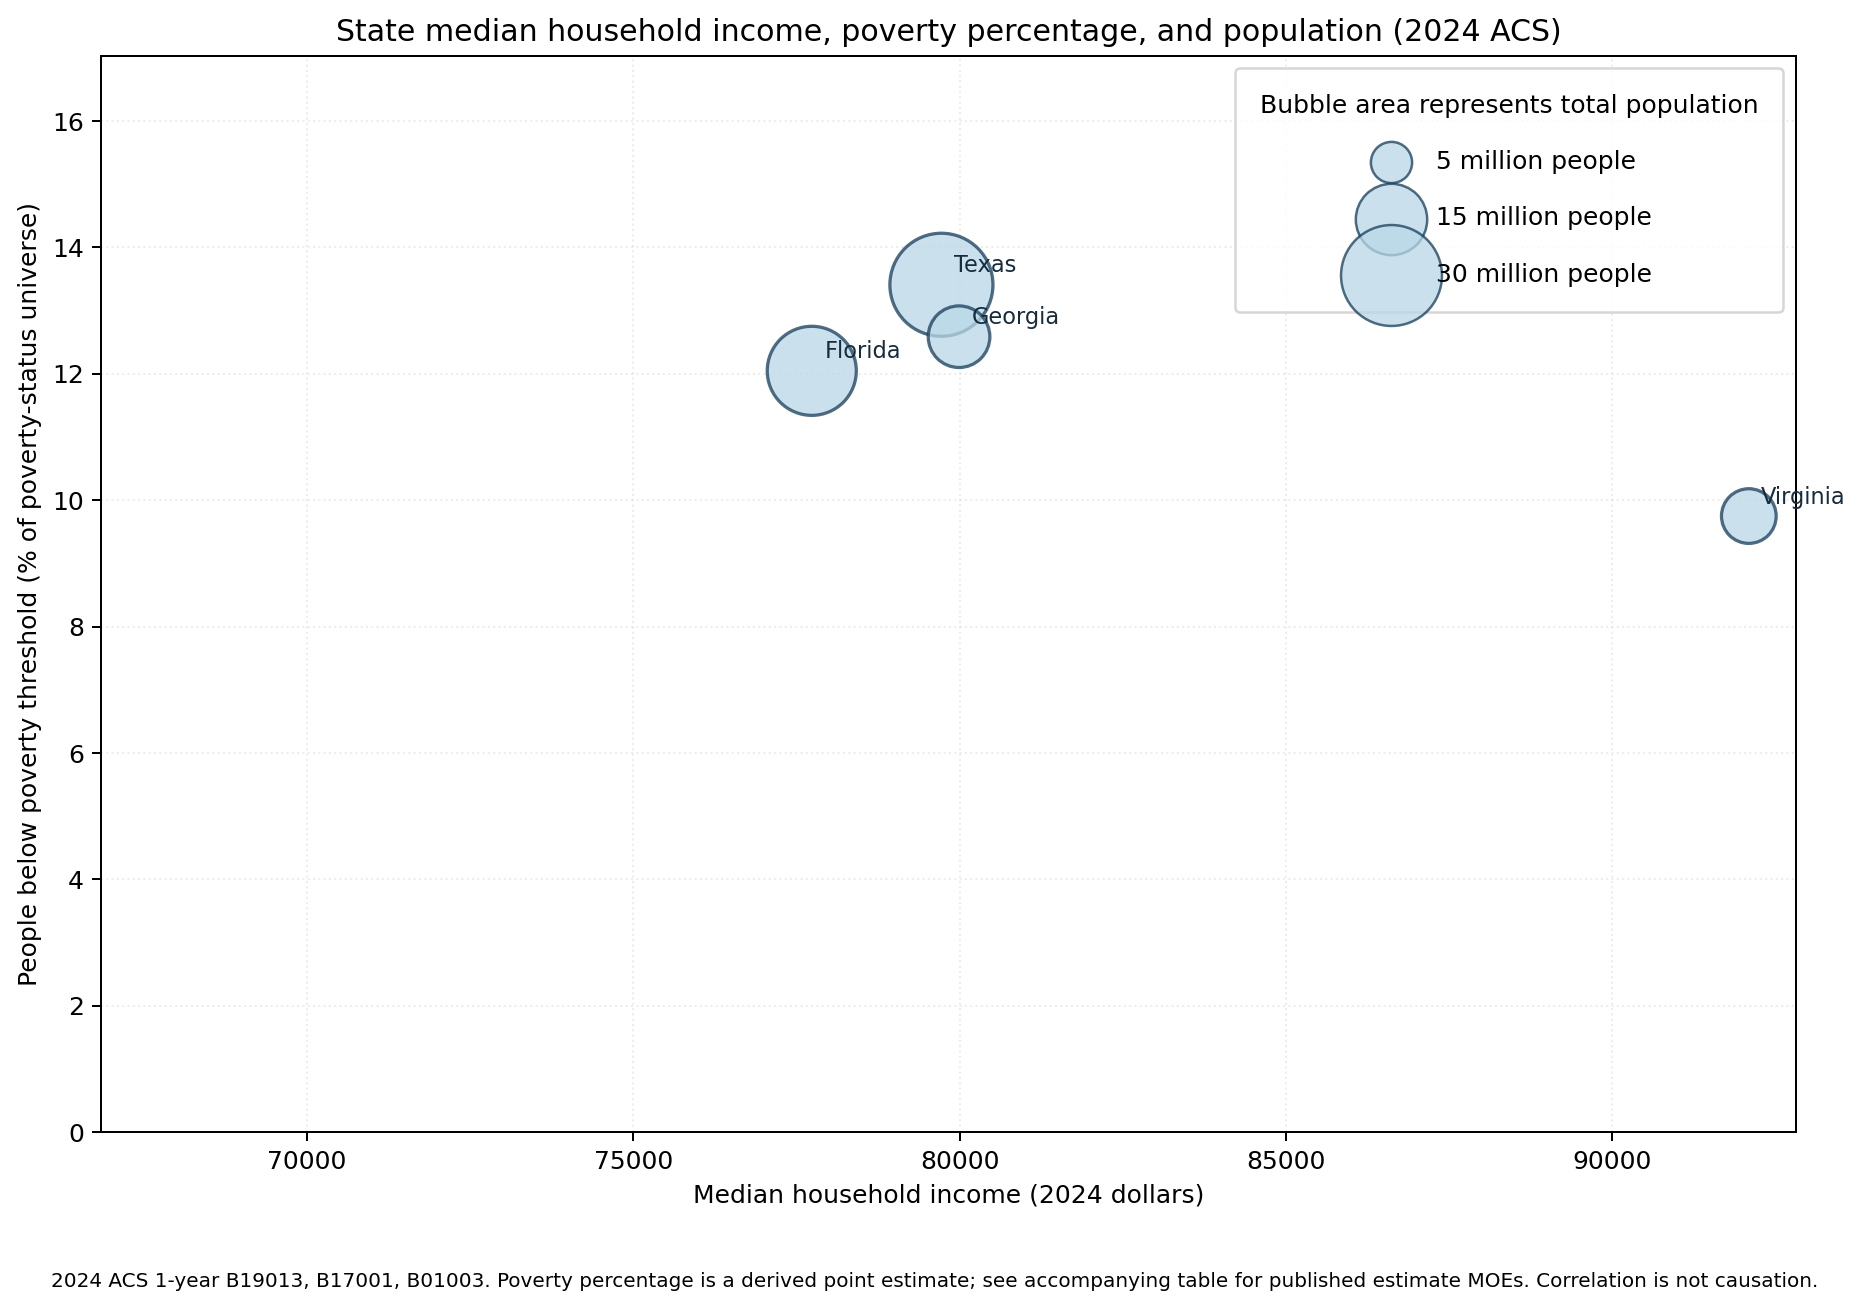

### histogram: histogram_acs.png

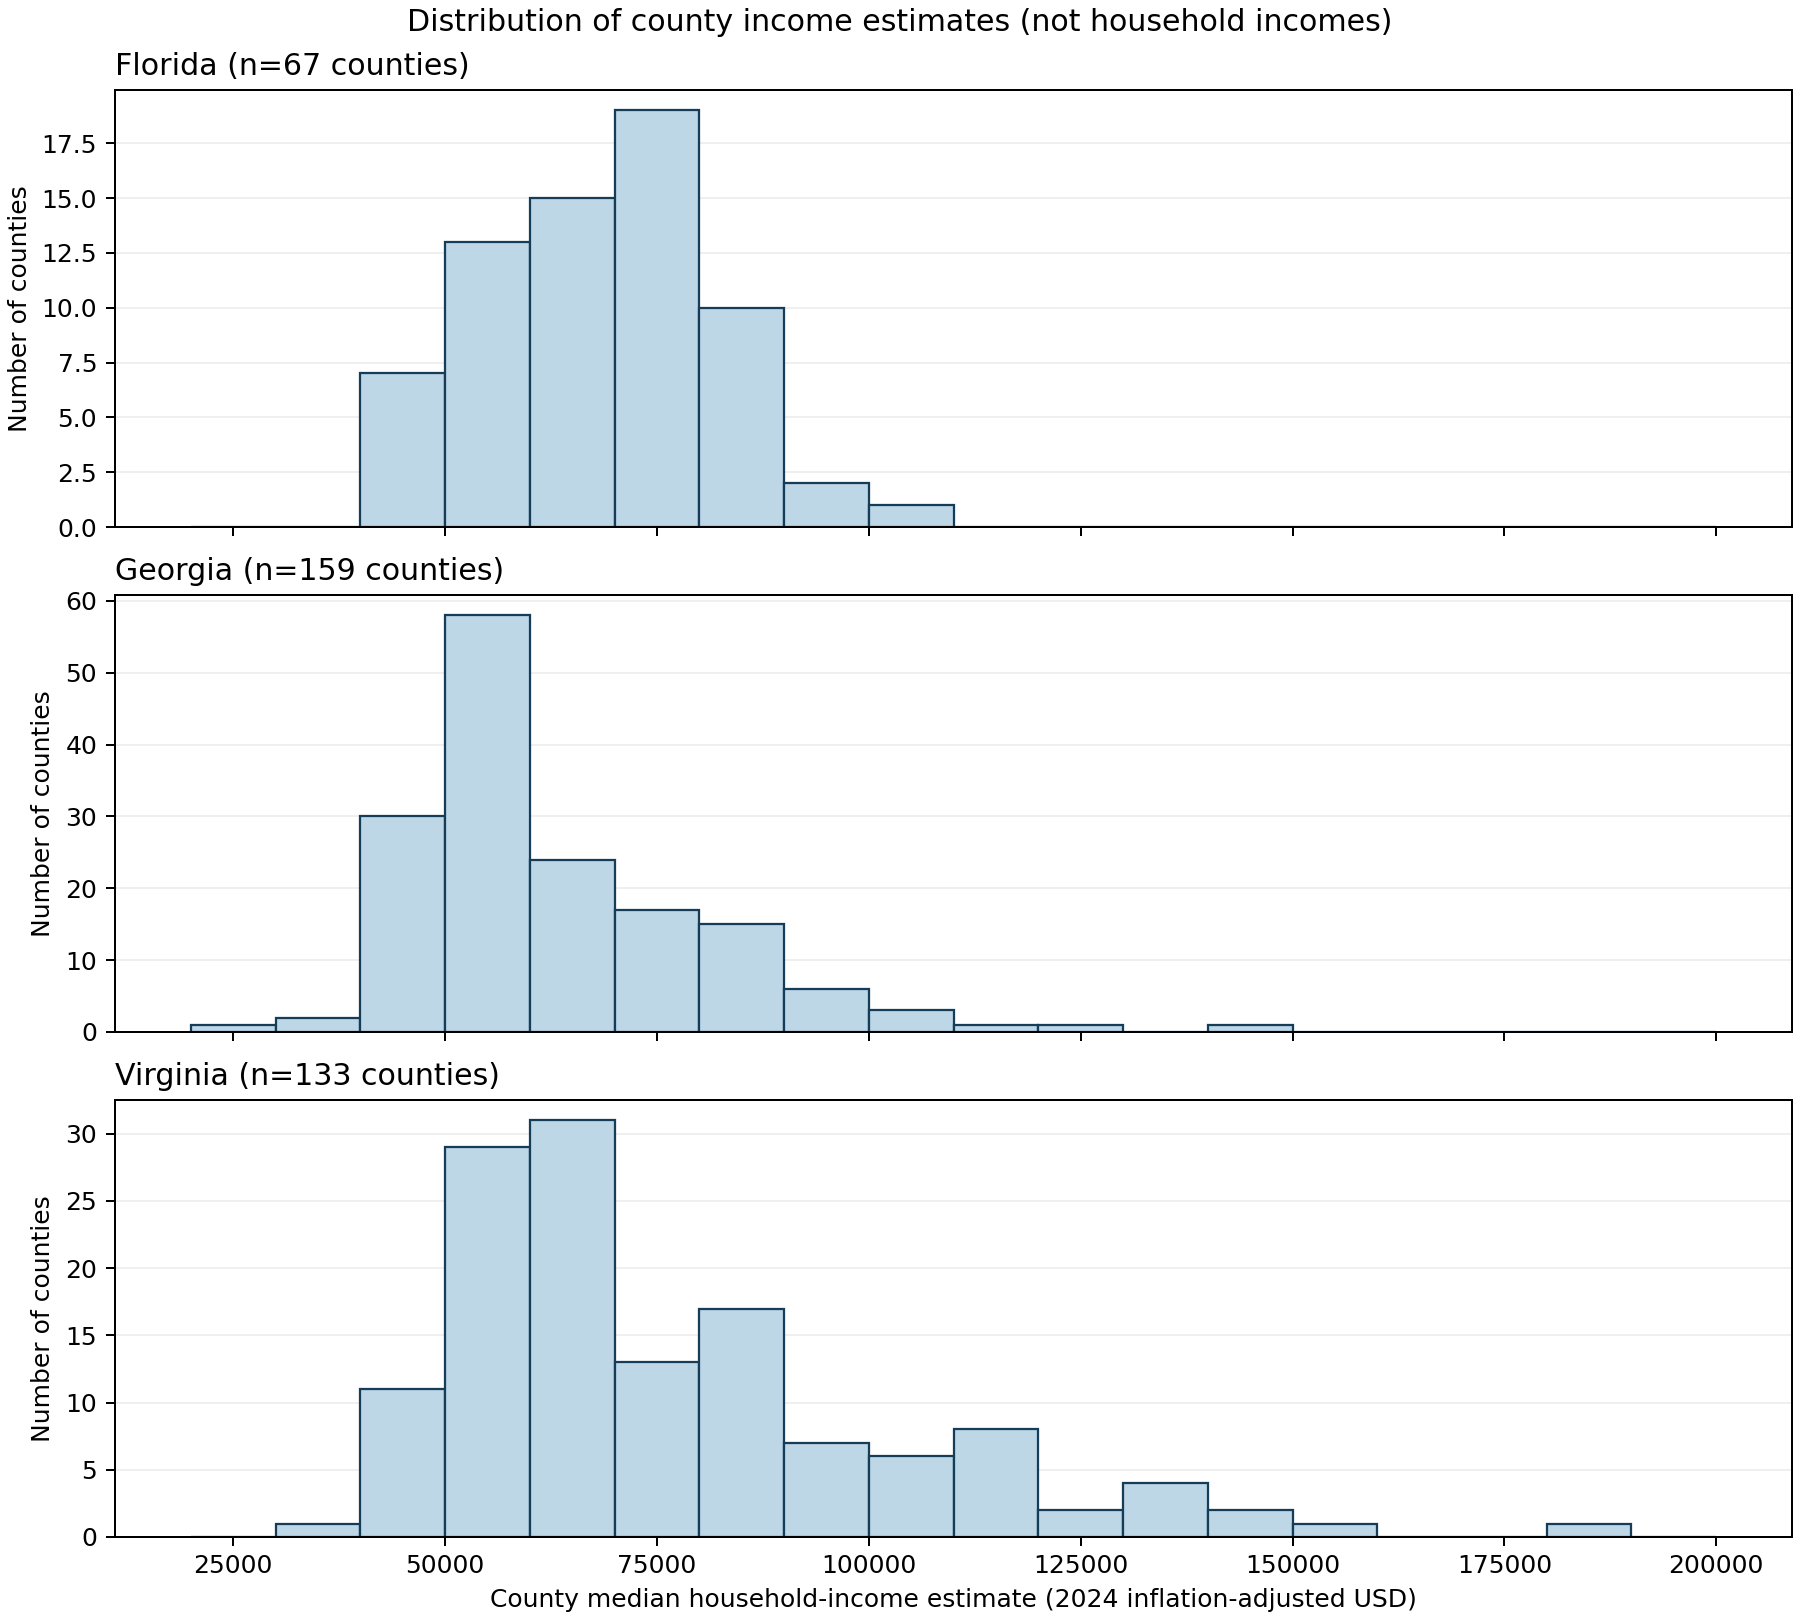

### line_graph: linegraph_acs_income.png

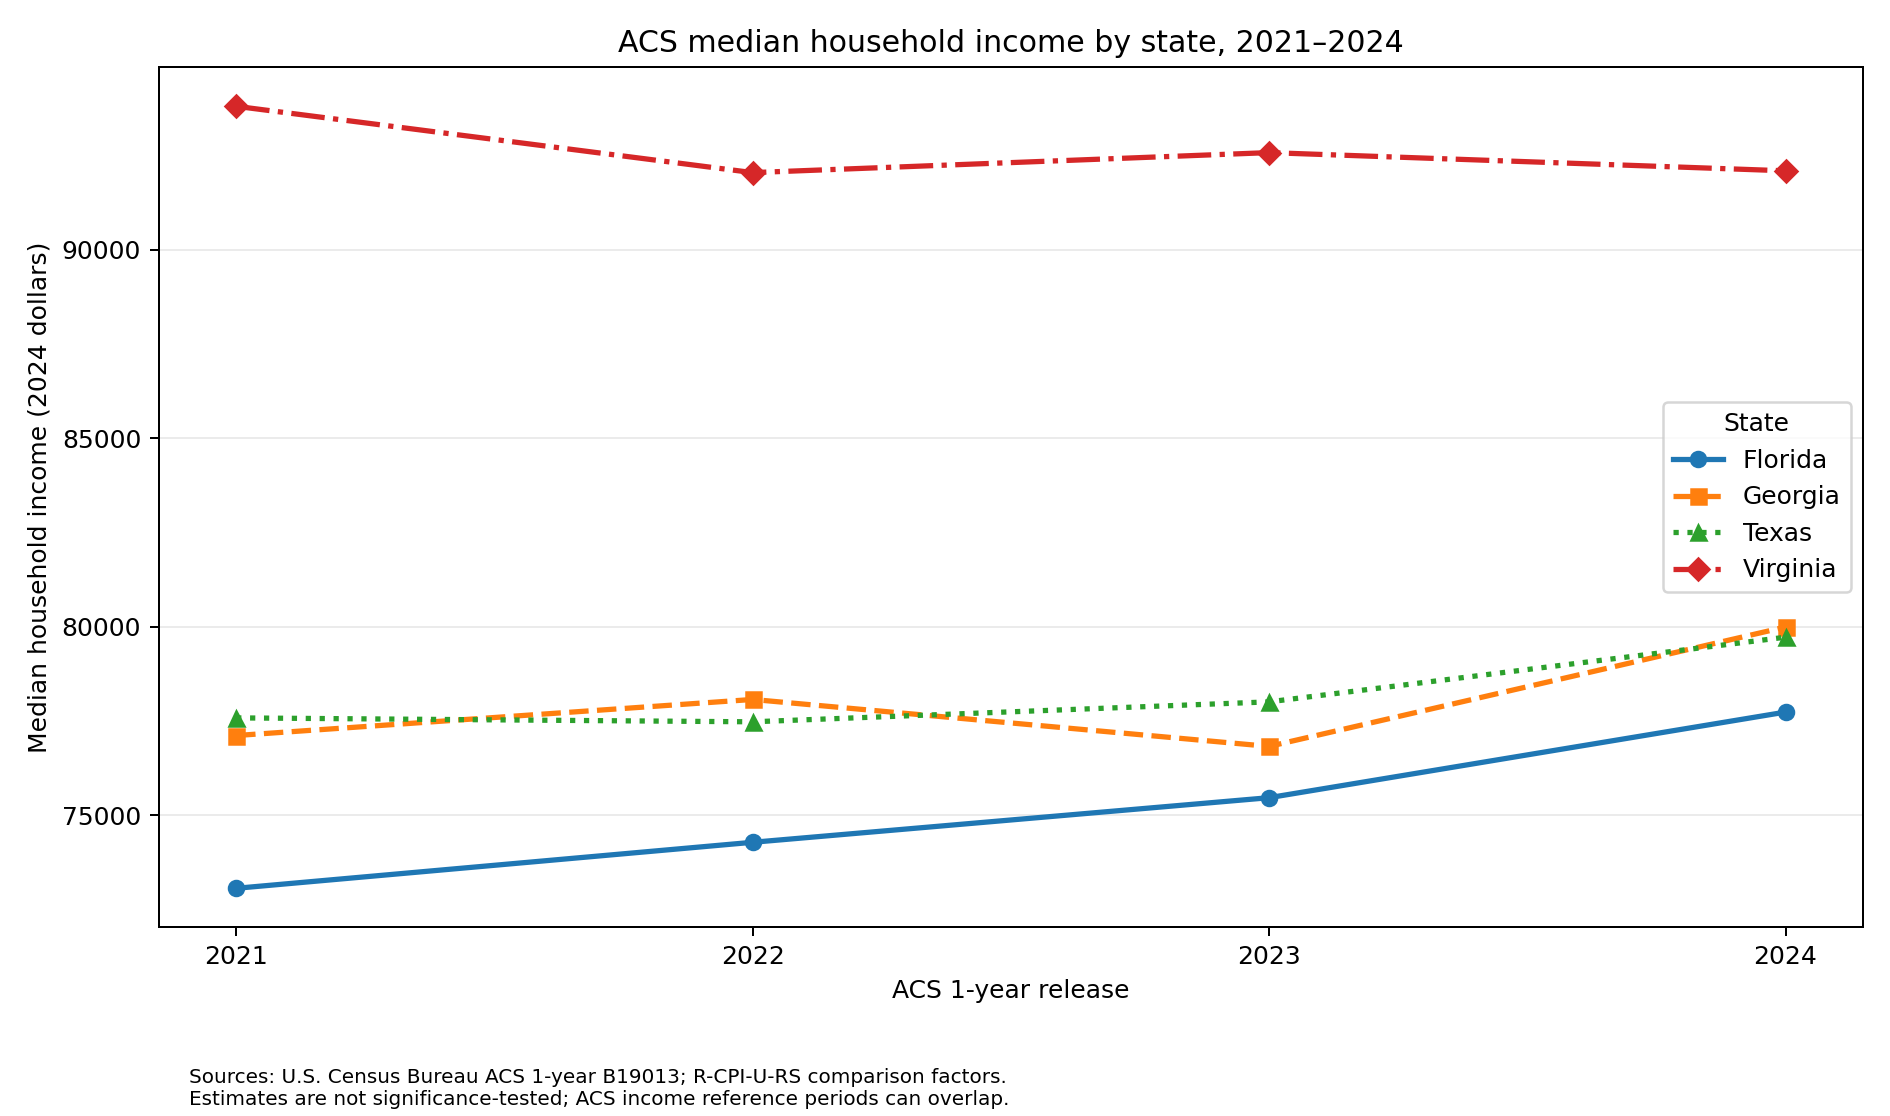

### nested_categories: nested_b03002.png

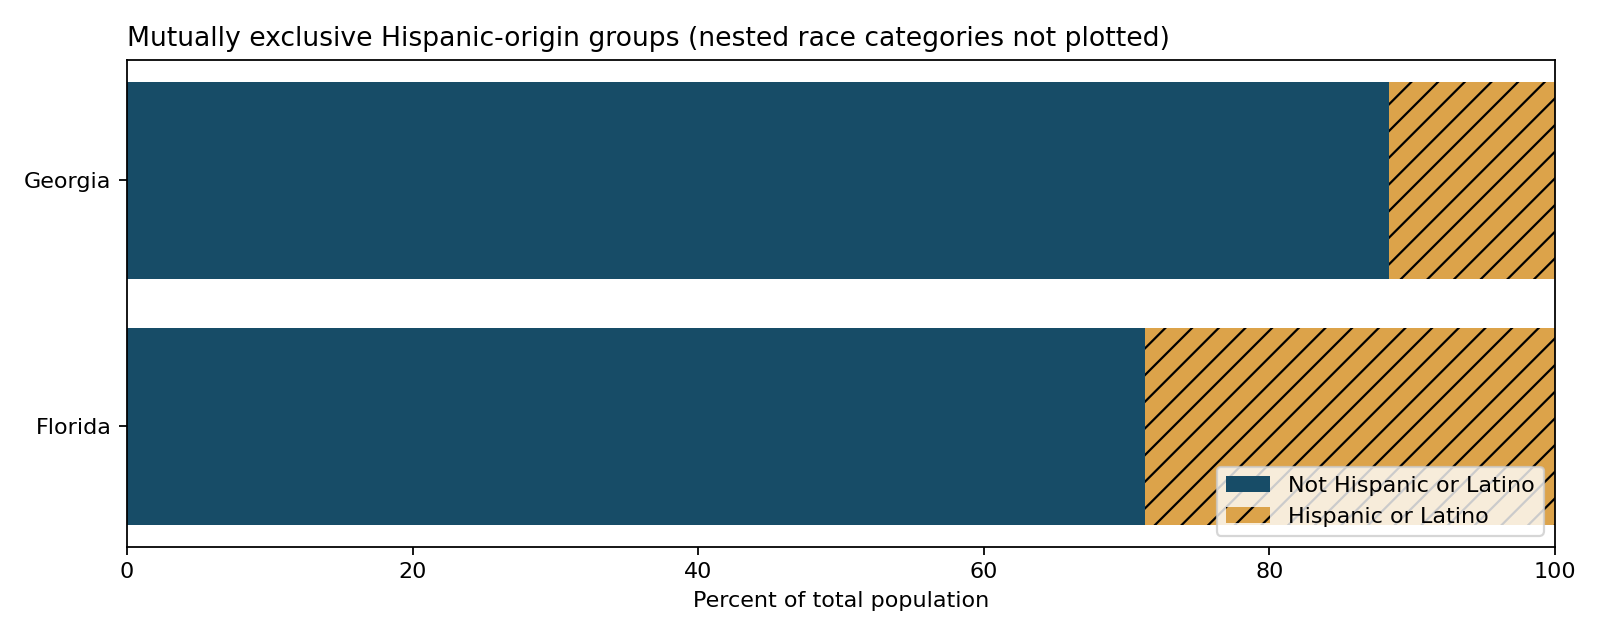

### nested_categories: nested_dp03.png

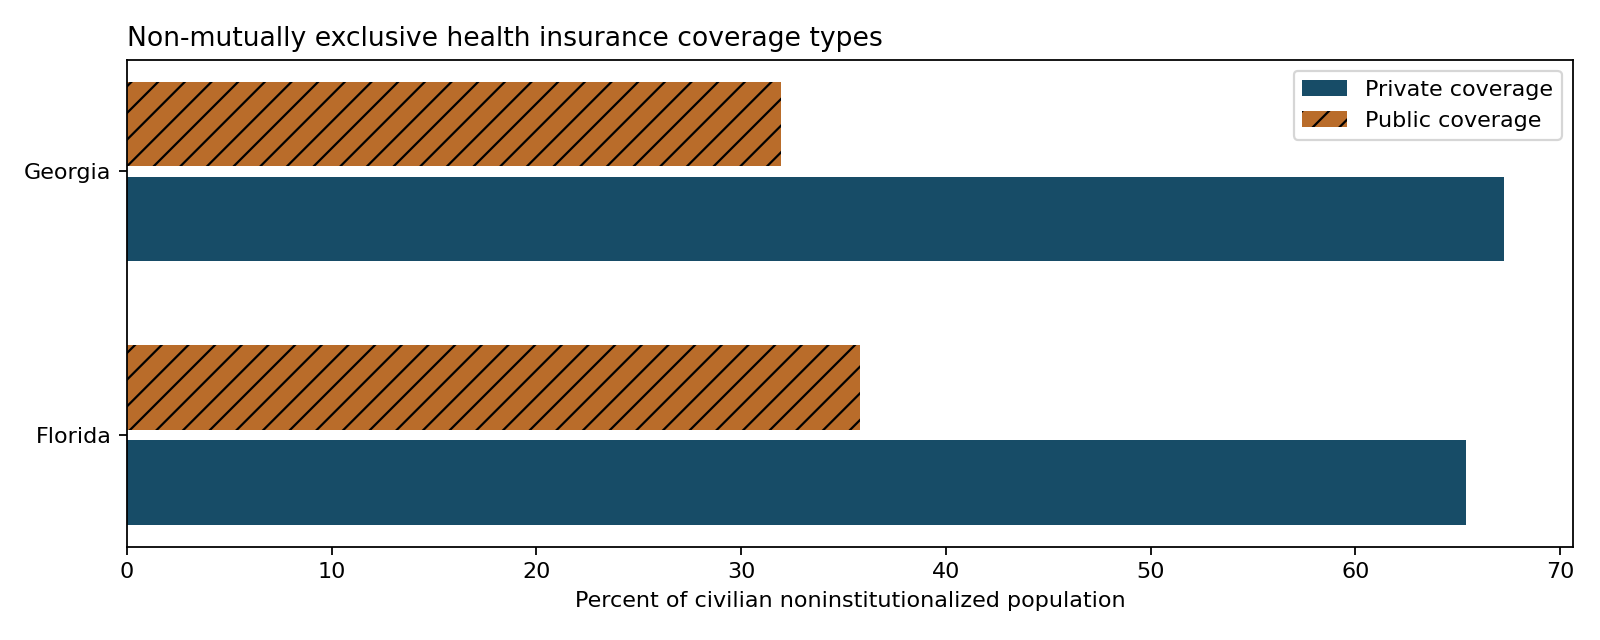

### population_pyramid: population_pyramid_acs.png

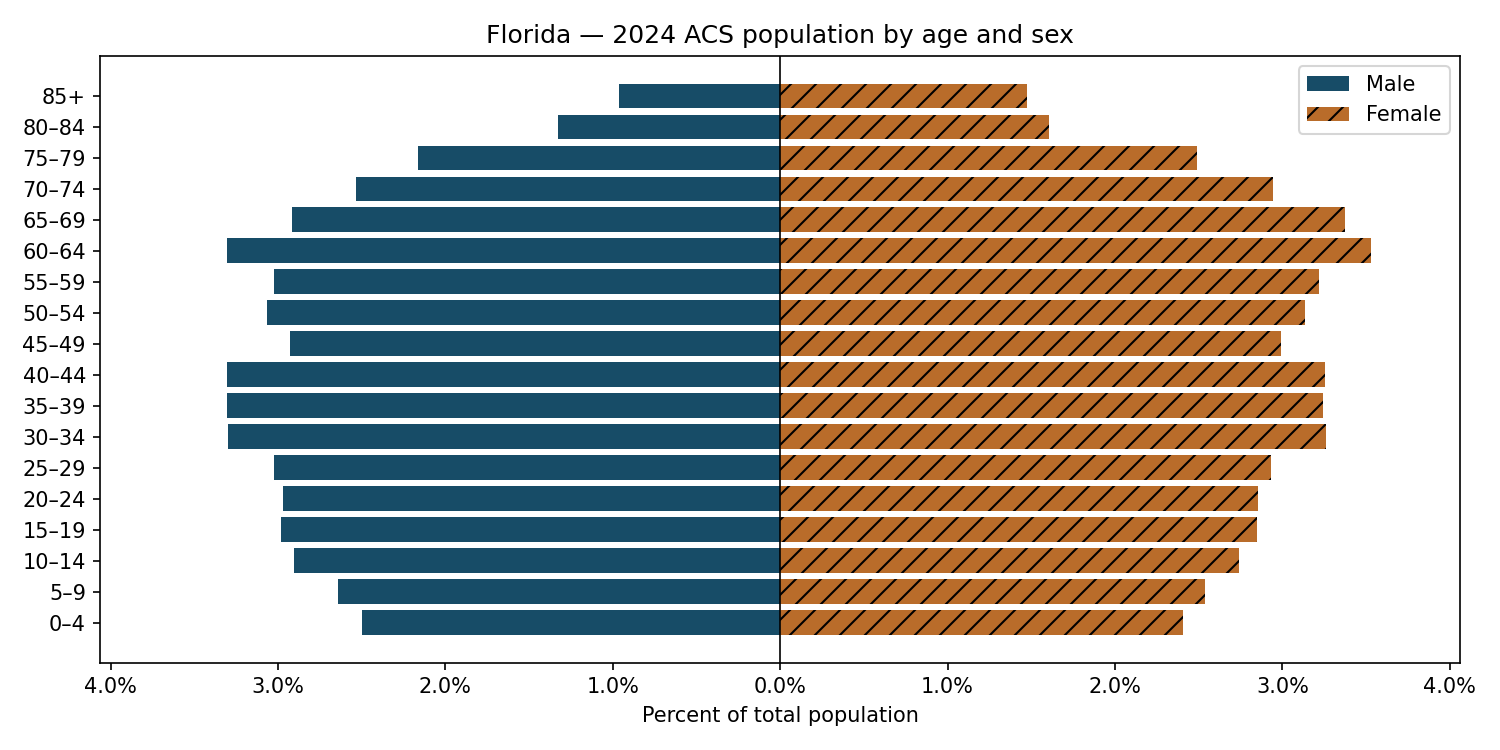

### scatter_plot: scatter_plot.png

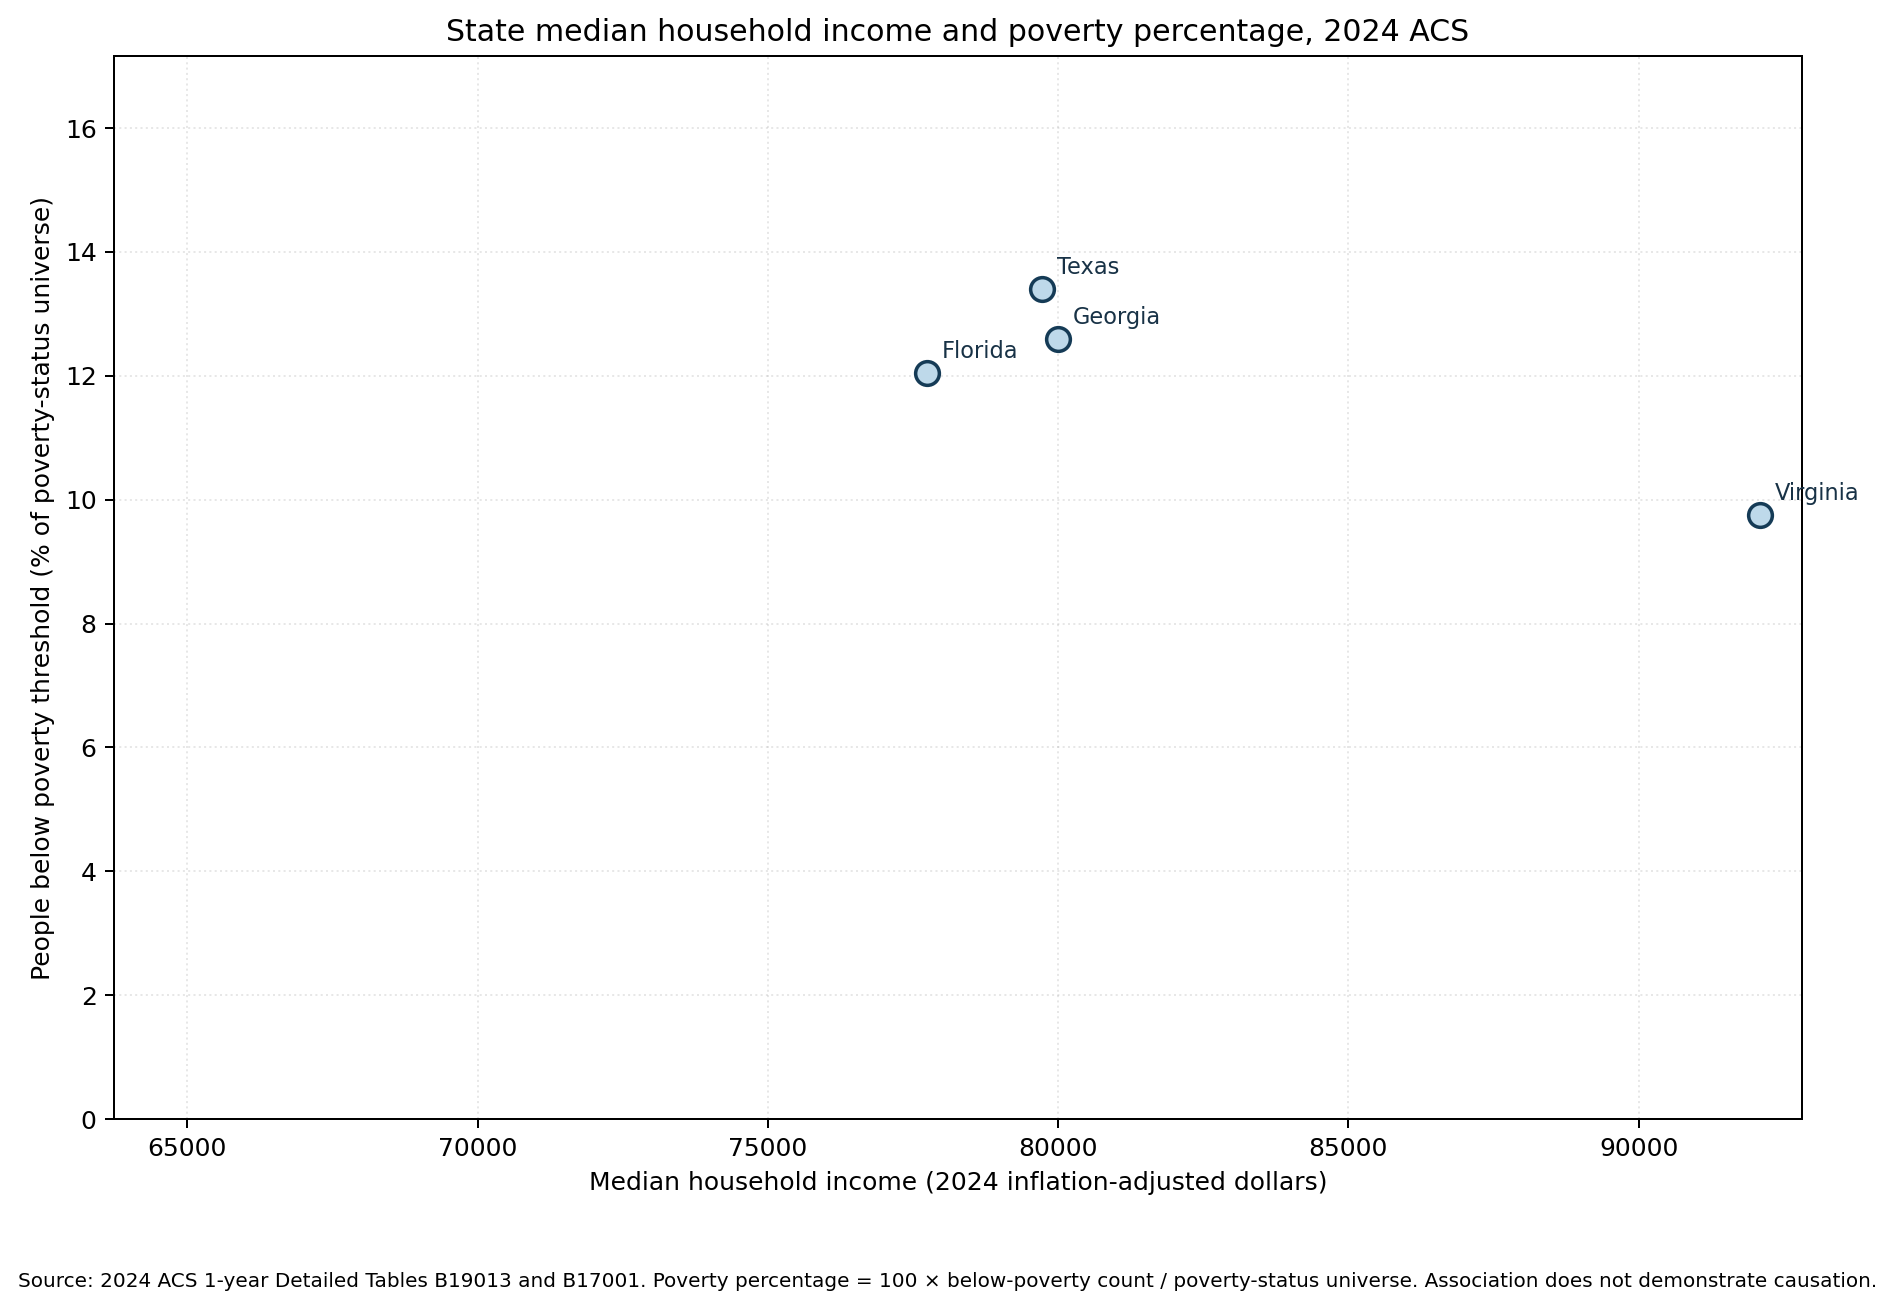

### small_multiples: small_multiples_acs.png

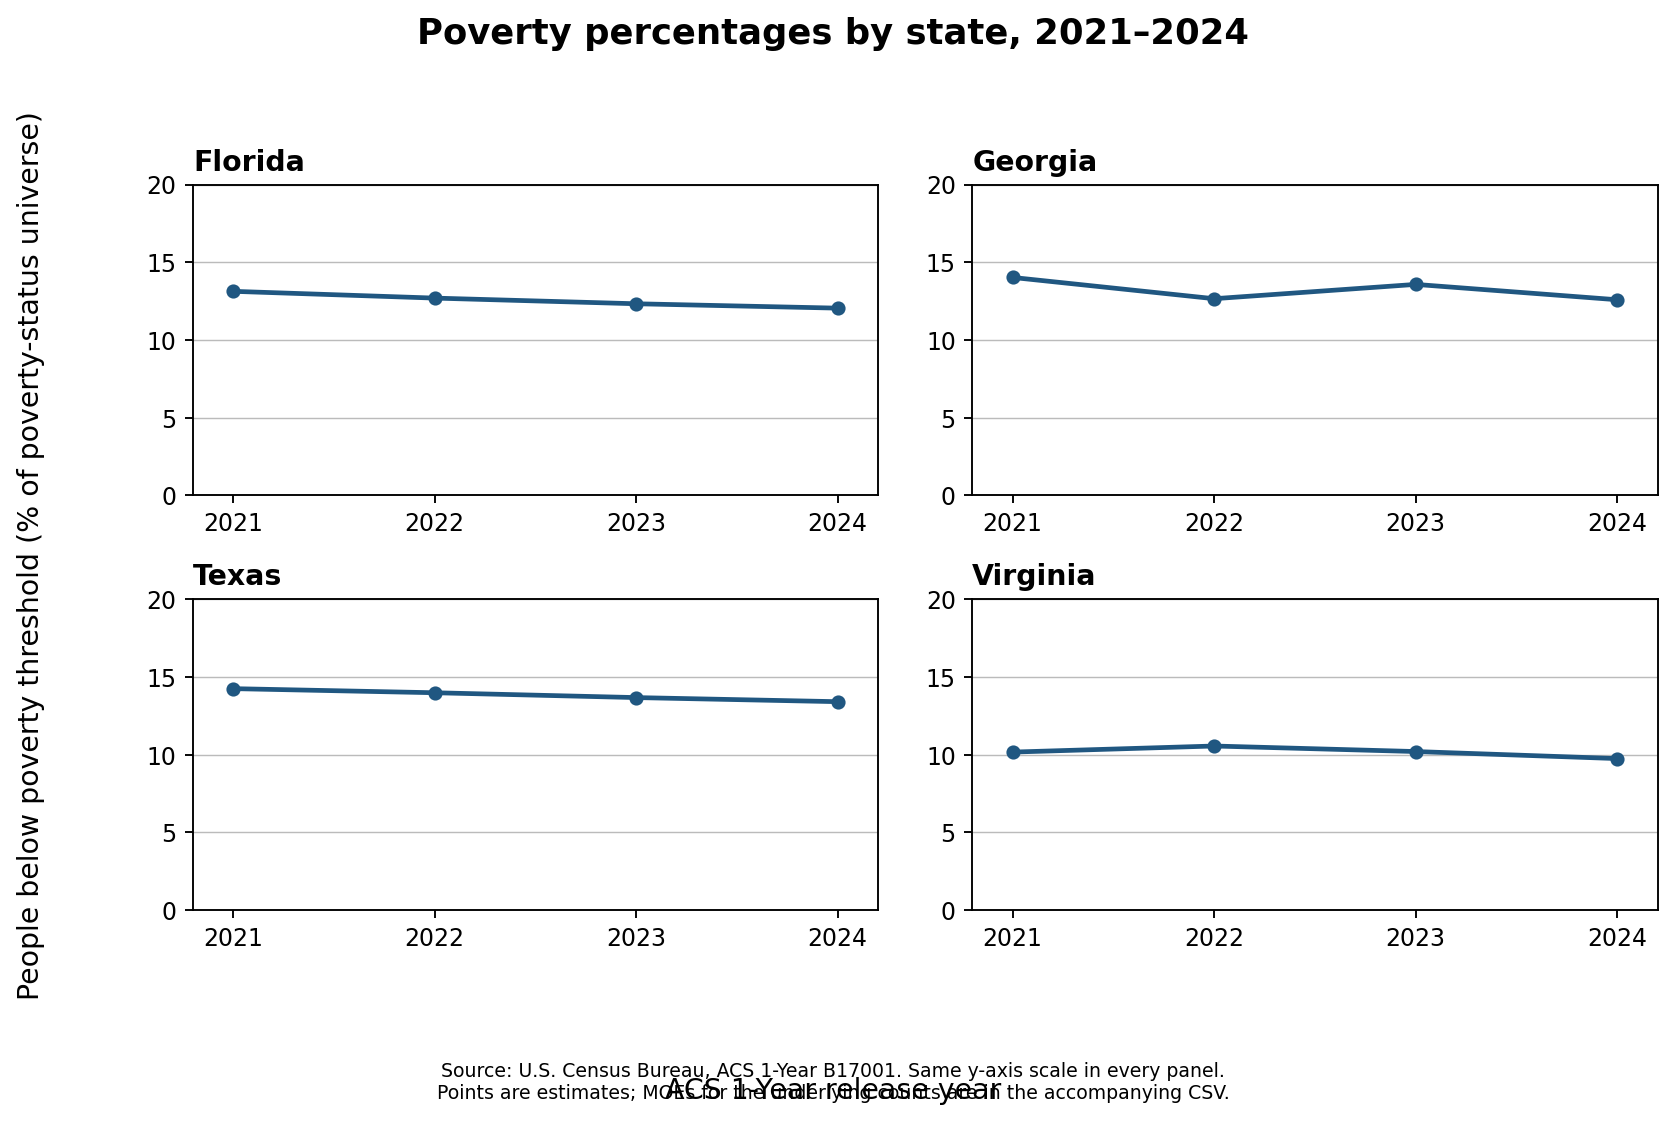

### stacked_area: stacked_area_florida.png

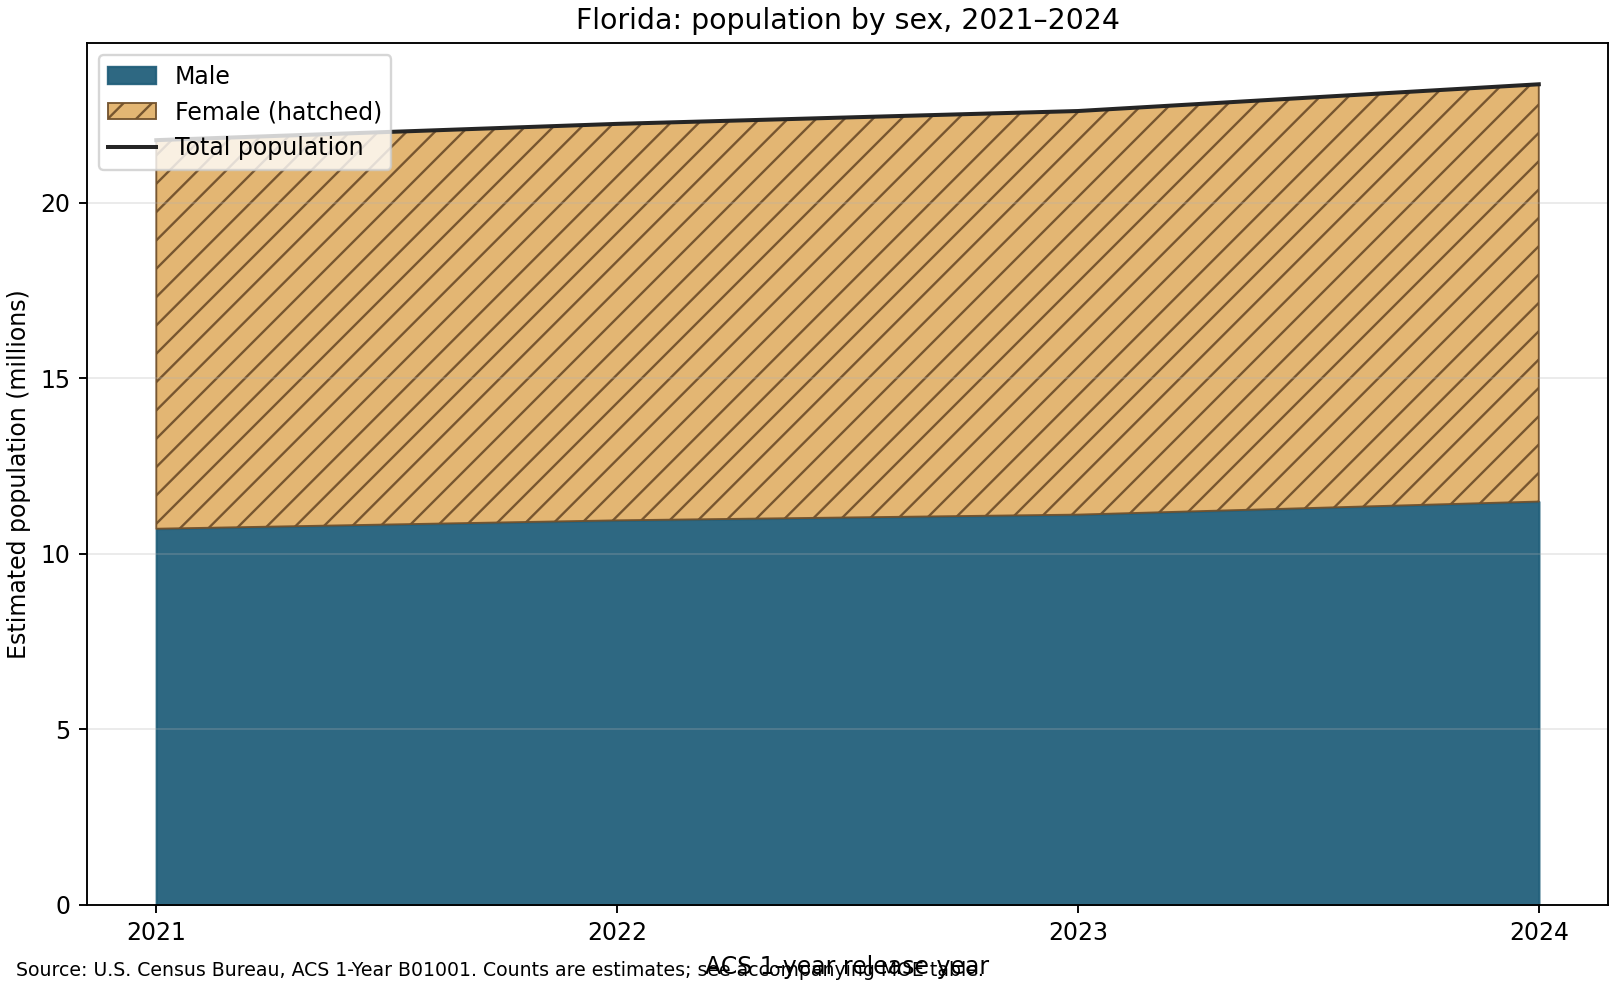

### stacked_area: stacked_area_georgia.png

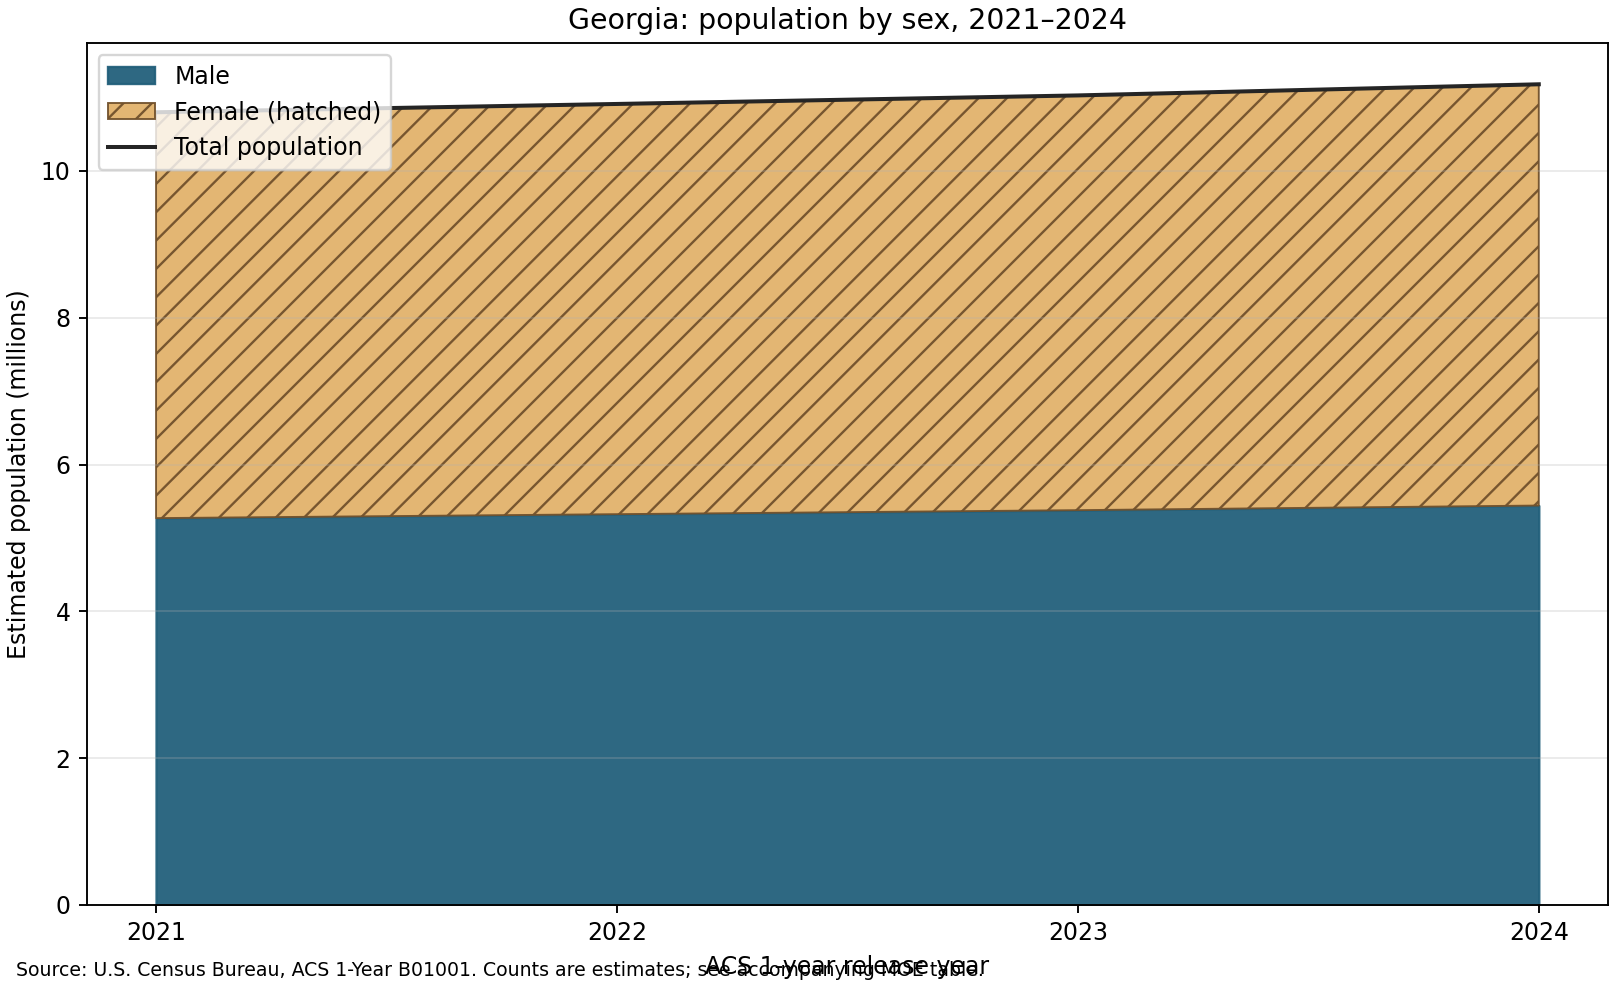

### uncertainty: uncertainty_acs.png

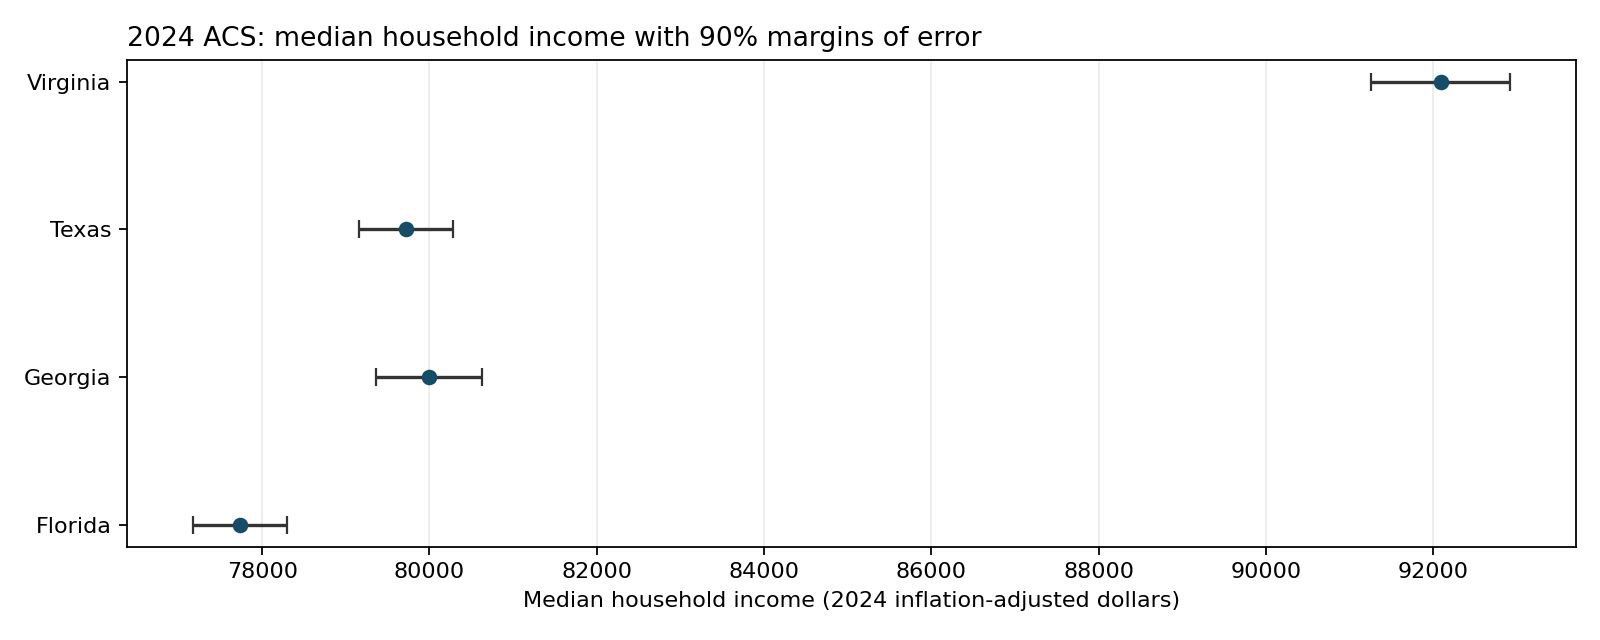

In [ ]:
import pandas as pd
from IPython.display import display, Image, Markdown
status = OUTPUT_ROOT / "execution_status.csv"
if status.exists():
    results = pd.read_csv(status).fillna("")
    display(results[["key", "status", "reason", "log_file"]])
    print("Generated:", (results.status == "generated_unreviewed").sum(),
          "| Failed:", (results.status == "failed").sum())
    pngs = sorted((OUTPUT_ROOT / "assets" / "examples").rglob("*.png"))
    print(f"PNG files generated: {len(pngs)}")
    for image_path in pngs:
        display(Markdown(f"### {image_path.parent.name}: {image_path.name}"))
        display(Image(filename=str(image_path), width=780))
    if not pngs:
        print("No charts were generated. See the reasons above; do not interpret an empty ZIP as success.")
else:
    print("No status report found. See the runner output and diagnostic messages in the previous cell.")


In [ ]:
# Optional: download only successfully produced files (does not modify chart values)
import shutil
if OUTPUT_ROOT.exists():
    target=shutil.make_archive(str(project/"ACS_Actual_Results"),"zip", root_dir=OUTPUT_ROOT)
    print("Results archive:", target)
    try:
        from google.colab import files
        files.download(target)
    except ImportError:
        print("Open this ZIP from your local filesystem")

Results archive: /content/ACS_Examples_Builder/ACS_Actual_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>